In [295]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

Question 2 

In [204]:
def uini(x):
    return np.sin(2*np.pi*x)

Question 3

b)

$\lambda = a \frac{\Delta t}{\Delta x}$

$\alpha = 1-\lambda$

$\beta = \lambda$

c) 

In [206]:
def schema(a,T,uini,J,lam):

    delta_x = 1/J
    
    X = np.linspace(0,1-delta_x,J)

    delta_t = lam*delta_x/a

    M = int(T/delta_t)

    tM = M*delta_t

    U = uini(X)

    U_barre = uini(X-a*tM)

    aux = U.copy()

    for n in range(M):

        U[0] = (1-lam)*aux[0] + lam*aux[J-1] # périodicité de u
        
        for j in range(1,J):

            U[j] = (1-lam)*aux[j] + lam*aux[j-1]

        aux = U.copy()

    return X,tM,U,U_barre

Question 4

Lorsque $\lambda = 1$, $a = \frac{\Delta x}{\Delta t}$

Ainsi, 

$\overline{u}(x_j,t_n) = u_{ini}(x_j - \frac{\Delta x}{\Delta t} t_n)
                        = u_{ini}(j \Delta x - n \Delta x)
                        = u_{ini}((j - n) \Delta x)$
                        
et comme $u_j^{n+1} = (1-\lambda)u_j^{n} + \lambda u_{j-1}^n$, et par réccurence on a : 

$u_{ini}((j - n) \Delta x) := u_{j-n}^{0} = u_{j}^{n} $

Question 5

In [266]:
a = 8

T = 20

J = 20

lam = 1

schema(a,T,uini,J,lam)[2]

array([ 0.00000000e+00,  3.09016994e-01,  5.87785252e-01,  8.09016994e-01,
        9.51056516e-01,  1.00000000e+00,  9.51056516e-01,  8.09016994e-01,
        5.87785252e-01,  3.09016994e-01,  5.66553890e-16, -3.09016994e-01,
       -5.87785252e-01, -8.09016994e-01, -9.51056516e-01, -1.00000000e+00,
       -9.51056516e-01, -8.09016994e-01, -5.87785252e-01, -3.09016994e-01])

In [268]:
schema(a,T,uini,J,lam)[3]

array([ 3.91886976e-14,  3.09016994e-01,  5.87785252e-01,  8.09016994e-01,
        9.51056516e-01,  1.00000000e+00,  9.51056516e-01,  8.09016994e-01,
        5.87785252e-01,  3.09016994e-01, -2.84080919e-14, -3.09016994e-01,
       -5.87785252e-01, -8.09016994e-01, -9.51056516e-01, -1.00000000e+00,
       -9.51056516e-01, -8.09016994e-01, -5.87785252e-01, -3.09016994e-01])

Question 6

In [212]:
def norme_inf(u,J):
 
    norm = np.abs(u)

    return np.max(norm)

In [214]:
def norme_2(u,J):
    
    delta_x = 1/J

    norm = np.sum(u**2)

    return np.sqrt(delta_x * norm)

In [254]:
def erreur(a,T,uini,J,lam,norm):

    delta_x = 1/J
    
    X = np.linspace(0,1-delta_x,J)

    delta_t = lam*delta_x/a

    M = int(T/delta_t)

    tM = M*delta_t

    U = uini(X)

    U_barre = uini(X)

    aux = U.copy()

    errmax = 0

    for n in range(M):

        U[0] = (1-lam)*aux[0] + lam*aux[J-1] # périodicité de u
        
        for j in range(1,J):

            U[j] = (1-lam)*aux[j] + lam*aux[j-1]

        U_barre = uini(X-a*(n+1)*delta_t)

        aux = U.copy()
        
        diff = U - U_barre

        erreur = norm(diff,J)
        
        if erreur > errmax :

            errmax = erreur

    if erreur > errmax :

        errmax = erreur

    return errmax

In [262]:
lam = 1

a = 8

T = 50

J = 50

erreur(a,T,uini,J,lam,norme_inf)

5.585809592645319e-13

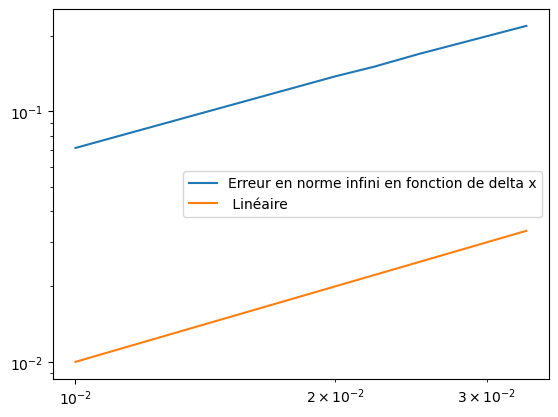

In [272]:
T_J = [30,40,45,50,100]

T_delta = np.array([1/J for J in T_J])

a = 1

T = 0.75

lam = 0.5

T_erreur_inf = [erreur(a,T,uini,J,lam,norme_inf) for J in T_J]

plt.loglog(T_delta,T_erreur_inf,label = "Erreur en norme infini en fonction de delta x")
plt.loglog(T_delta,T_delta, label= " Linéaire ")
#plt.loglog(T_delta,T_delta**2, label = " Quadratique ")
plt.legend()
plt.show()

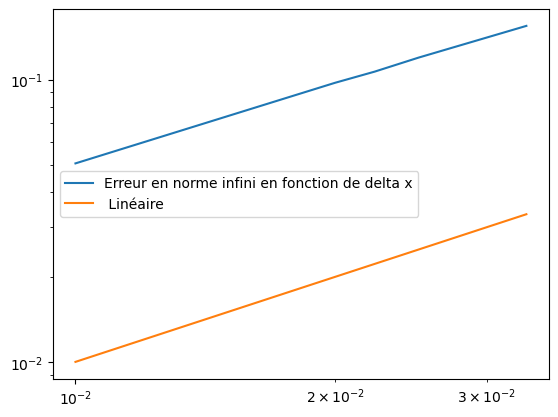

In [276]:
T_J = [30,40,45,50,100]

T_delta = np.array([1/J for J in T_J])

a = 1

T = 0.75

lam = 0.5

T_erreur_2 = [erreur(a,T,uini,J,lam,norme_2) for J in T_J]

plt.loglog(T_delta,T_erreur_2,label = "Erreur en norme infini en fonction de delta x")
plt.loglog(T_delta,T_delta, label= " Linéaire ")
#plt.loglog(T_delta,T_delta**2, label = " Quadratique ")
plt.legend()
plt.show()